<a href="https://colab.research.google.com/github/jghazaly/MPM_200_Ghazaly/blob/main/Notebooks/assignment_1_will__hummers_survive_Ghazaly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [15]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

#Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [16]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Jameela!", by = "owl")


 _________________________________________ 
< Welcome to Hummingbird HQ, Dr. Jameela! >
 ----------------------------------------- 
    \
     \

       /\___/\
       {o}{o}|
       \ v  /|
       |    \ \
        \___/_/       [ab]
          | |

In [17]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [29]:
url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200_2026/main/data/Hummingbird_data_Jameela.csv"
data <- read.csv("Hummingbird_data_Jameela.csv")
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

6908, by applying this code length(unique(data$ID)) it
tells you how many unique (not repeated bird ID) and
their lenght (how many are they)

In [25]:
dim(data)      # rows, columns
nrow(data)
ncol(data)
length(unique(data$ID))

[1] 5000   12

[1] 5000

[1] 12

[1] 5000

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [26]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "4/30/2016" "6/9/2014" "6/3/2006" "4/30/1994" ...
 $ Disposition_binary: chr  "Died" "Released" "Released" "Died" ...
 $ Place             : chr  "Lindsey" "malibu" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "No" "No" ...
 $ Species_e         : chr  "ANHU" "Selasphorus" "Non-selasphorus" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "unknown" "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "Nestling" "adult-like" ...
 $ Brought_in_after  : int  0 0 0 0 9 1 0 1 0 0 ...
 $ season            : chr  "Spring" "Summer" "Summer" "Spring" ...
 $ r                 : chr  "found on the ground" "unknown" "found on the ground" "found inside" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "5593_ANHU" "6261_ALHU" "3100_ANHU" "632_ANHU" ...
          Admitted Dis

✍️ **Your answer:** 1-Text characters are 11 out of 12. 12- Numerical (integer) is only 1 (Brought_in_after). 3- Admitted is stored as character 4-Other errors: "Female-like " has an extra space at the end. r is not so specific maybe a short cut for reason but not clear.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [27]:
set.seed(2408)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [28]:
dim(model_data)
str(model_data)

[1] 5000   12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "5/28/2014" "5/7/2006" "6/6/2014" "4/3/1997" ...
 $ Disposition_binary: chr  "Died" "Died" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "Yes" "No" ...
 $ Species_e         : chr  "Non-selasphorus" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "unknown" "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "Nestling" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 1 0 0 1 0 0 0 0 ...
 $ season            : chr  "Spring" "Spring" "Summer" "Spring" ...
 $ r                 : chr  "nest-related" "found on the ground" "window hit" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "5016_ANHU" "3087_ANHU" "5030_ANHU" "1202_ANHU" ...


**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:** 11 are categorical and one continuous. No ID isn't useful because it only tells the bird identification and its own or individual record also it is not a useful variable to compare a specific outcome.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [30]:
write.csv(model_data, "outputs/Hummingbird_data_Jameela.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [31]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4159
Santa Barbara,64
malibu,777


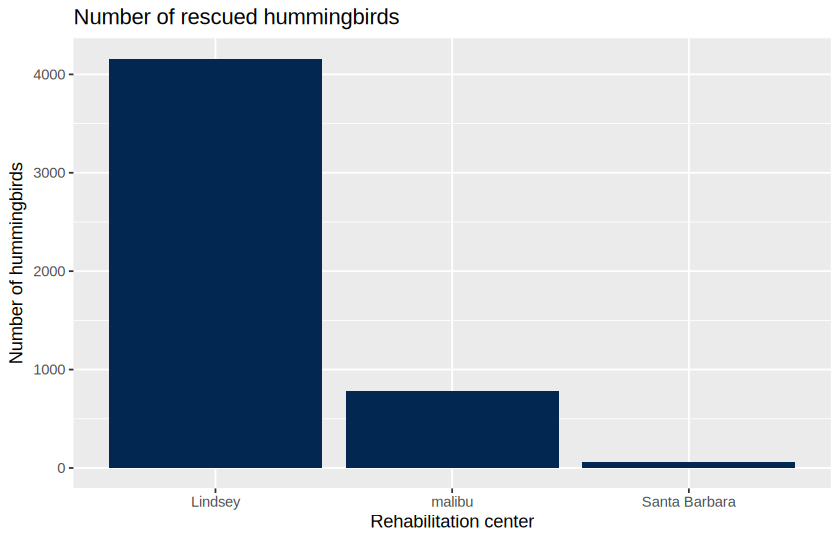

In [32]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [33]:
ggsave("outputs/rehab_counts_Jameela.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**  **First line:** start with your subset that you created from data, which is model_data. By using the pipe from the dyplr package do the following. **Second line:** Group the birds by their place or the rehab center they were at. **Third line:** for each group sorted summarize the following: the count or the number of unique birds in each group. **Fourth line:** ask R to show the results. **Fifth line or next code:** Make a plot using the ggplot with using the rehab table and putting the x = Place or rehab center and y = count of birds.**Sixth line :** fill the column with this color code. **Seventh line: **Call the x axis rehabilition center and **Eight line:** y axis number of huming birds. lastly, the **ninght line:** call the title of the plot: Number of rescued humming birds.


**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:** Because raw counts doesnt tell you the percentage or case fatalitly proportion and that case we need those number to compare. Also, we might need to know other factors that could contribute to death. It doesn't mean that Lindsery center admitted more that the deaths are technicaly high and we need to understand other factor and percenatges in comaprison with others

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [34]:
df <- model_data %>%
  group_by(r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

r,Disposition_binary,count
<chr>,<chr>,<int>
caught by domestic animal,Died,481
caught by domestic animal,Released,169
found inside,Died,125
found inside,Released,47
found on the ground,Died,1405
found on the ground,Released,722
nest-related,Died,265
nest-related,Released,411
suspect torpor-like state,Died,89


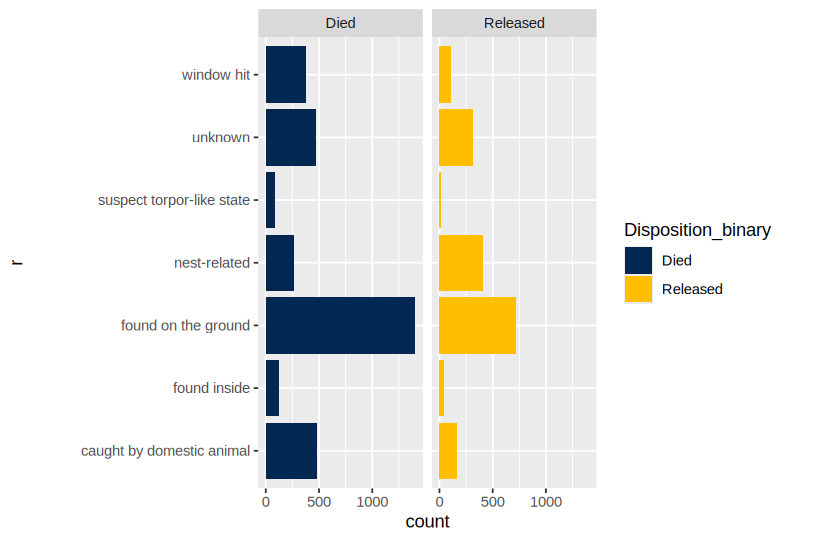

In [35]:
ggplot(df, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ By running three variable, it looks like age and r (reason) associated with survival however, for frist aid the results were almost similar. A statistical test that could be useful here is the test of proportions. First aid doesn't make a diiference and results are similar. for the r variable, nest-related birds did their bestest, with only 39% dying. For the age variable. adult birds died more like around 70 something percent and nestling we less only about 35%.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2695,0.6479923
Lindsey,Released,1464,0.3520077
Santa Barbara,Died,36,0.5625000
Santa Barbara,Released,28,0.4375000
malibu,Died,486,0.6254826
malibu,Released,291,0.3745174


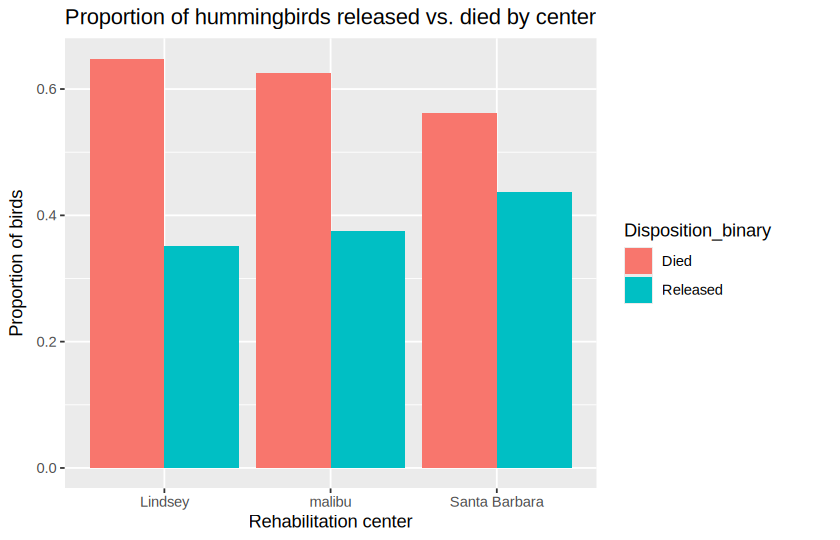

In [36]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation center") +
  ylab("Proportion of birds") +
  labs(title = "Proportion of hummingbirds released vs. died by center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                      
                       Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus spp.                 4142                0
  Selasphorus spp.                        0              858

Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Non-selasphorus spp.,Died,2676,0.6460647
Non-selasphorus spp.,Released,1466,0.3539353
Selasphorus spp.,Died,541,0.6305361
Selasphorus spp.,Released,317,0.3694639


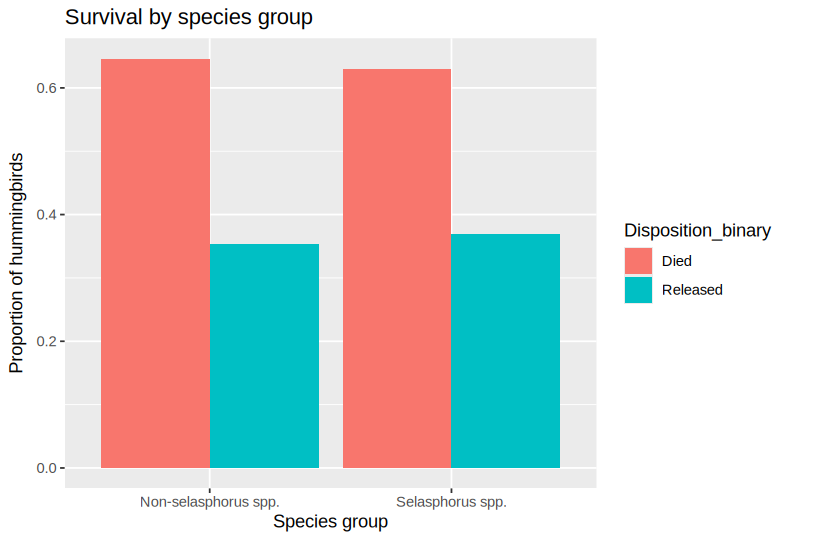

In [37]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus",
                                   "Selasphorus spp.",
                                   "Non-selasphorus spp.")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Species_group) %>%
  mutate(proportion = count / sum(count))
species_distribution

ggplot(species_distribution, aes(x = Species_group, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species group") +
  ylab("Proportion of hummingbirds") +
  labs(title = "Survival by species group")

✍️ **Your answer:**

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [38]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ *
The format argument tells R how the dates are written in our data. Our dates are month/day/year (like 4/30/2016), so we use “%m/%d/%Y”. If we used “%d/%m/%Y” instead, R would mix up the day and the month. For a date like 4/30/2016, R will think the month is 30, which doesn’t happen, so it would give NA. For dates like 1/2/1991, R wouldn’t give an error, but it would read it as February 1 instead of January 2, so the date would just be wrong without us noticing.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Spring` Why? nesting season or yuong birds lerarning how to fly.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [45]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n_distinct(ID))

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n_distinct(ID))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_month and Species_group.
ℹ Output is grouped by Admitted_month.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_month, Species_group))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


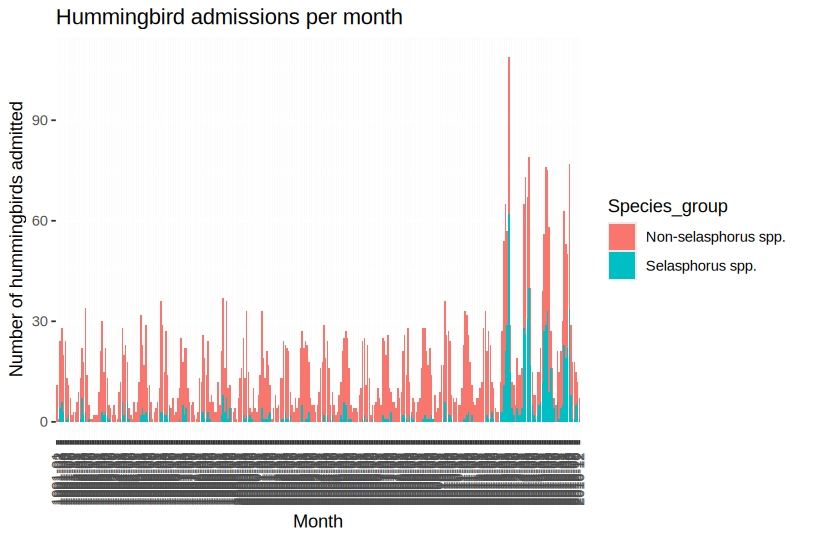

In [46]:
ggplot(admissions_by_month, aes(x = Admitted_month, y = count, fill= Species_group)) +
  geom_col() +
  xlab("Month") +
  ylab("Number of hummingbirds admitted") +
  labs(title = "Hummingbird admissions per month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

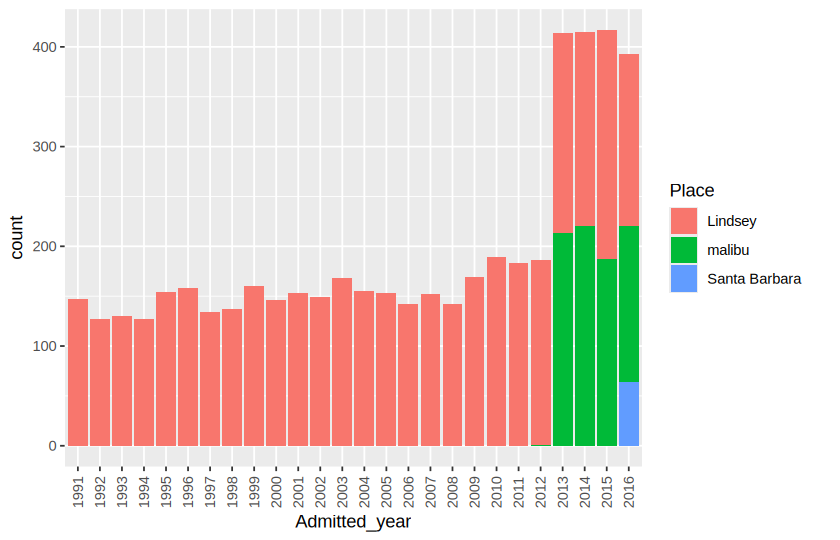

In [41]:
model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year, Place) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  ggplot(aes(x = Admitted_year, y = count, fill = Place)) +
  geom_col() +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

✍️ **Your answer:** No, hummingbirds didn’t suddenly get into three times more trouble. Before 2013, only Lindsey was reporting data. In 2013, Malibu started adding its records, and in 2016 Santa Barbara joined too. Lindsey’s numbers stayed about the same, so the increase came from more centers reporting, not from more birds getting hurt

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [42]:
# Problem 1: Sex_e has extra spaces at the end
unique(data$Sex_e)

# Problem 2: Place has inconsistent capitalization
unique(data$Place)

# Problem 3: Admitted is stored as text, not a date
class(data$Admitted)

# Fix: make a cleaned copy so the raw data stays the same
data_clean <- data %>%
  mutate(Sex_e = trimws(Sex_e),
         Place = tools::toTitleCase(Place),
         Admitted = as.Date(Admitted, format = "%m/%d/%Y"))

[1] "Female-like " "unknown"      "Male"

[1] "Lindsey"       "malibu"        "Santa Barbara"

[1] "character"

✍️ **Your answer:**  I found three problems in the raw data. First, the Sex_e column has extra spaces at the end, like “Female-like “, which can cause problems when grouping or filtering. I would fix it with trimws(). Second, the Place names aren’t written the same way: “Lindsey” is capitalized but “malibu” isn’t. I would fix this by making all the names start with a capital letter. Third, the Admitted column is saved as text instead of a date, so R can’t use it as a date. I would fix it with as.Date(). I would save all these changes in a new object called data_clean, so the original raw data doesn’t change.

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**  One thing that surprised me was that first aid didn’t really make a difference in survival, and that nestlings survived better than adult birds. I also hit an error when reading the CSV file because R couldn’t find it. I fixed it by adding the folder name to the path (“sample_data/Hummingbird_data.csv”).

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [ ]:
beep_colab("smb_stage_clear")   # mission complete 🍄